**Import Libraries**

In [ ]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

**Task 6: Feature Selection**



* We used a barplot to visualize the feature importance base on correolation.




In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

* We used a barplot to visualize the feature importance base on Mutual information and selectKBest.


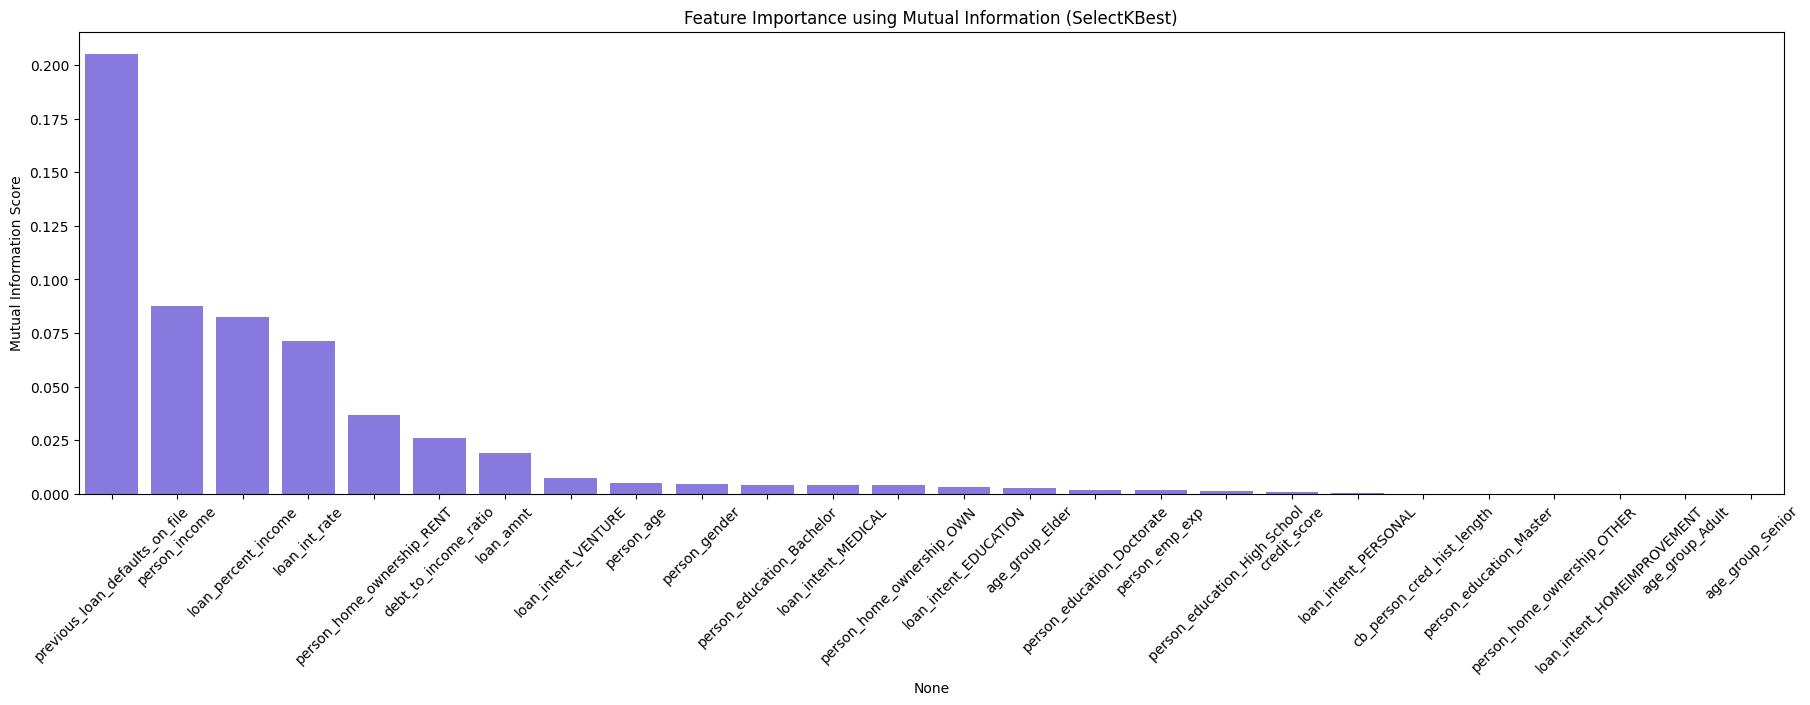

In [ ]:
X = df_final.drop('loan_status', axis=1)
y = df_final['loan_status']

# SelectKBest with Mutual Information
kbest_selector = SelectKBest(score_func=mutual_info_classif, k='all')
kbest_selector.fit(X, y)
kbest_scores = pd.Series(kbest_selector.scores_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(22,6))
sns.barplot(x=kbest_scores.index, y=kbest_scores.values, color="mediumslateblue")
plt.xticks(rotation=45)
plt.ylabel("Mutual Information Score")
plt.title("Feature Importance using Mutual Information (SelectKBest)")
plt.show()

* We used a barplot to visualize the feature importance base on Random forest.


Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_HOMEIMPROVEMENT', 'debt_to_income_ratio'],
      dtype='object')


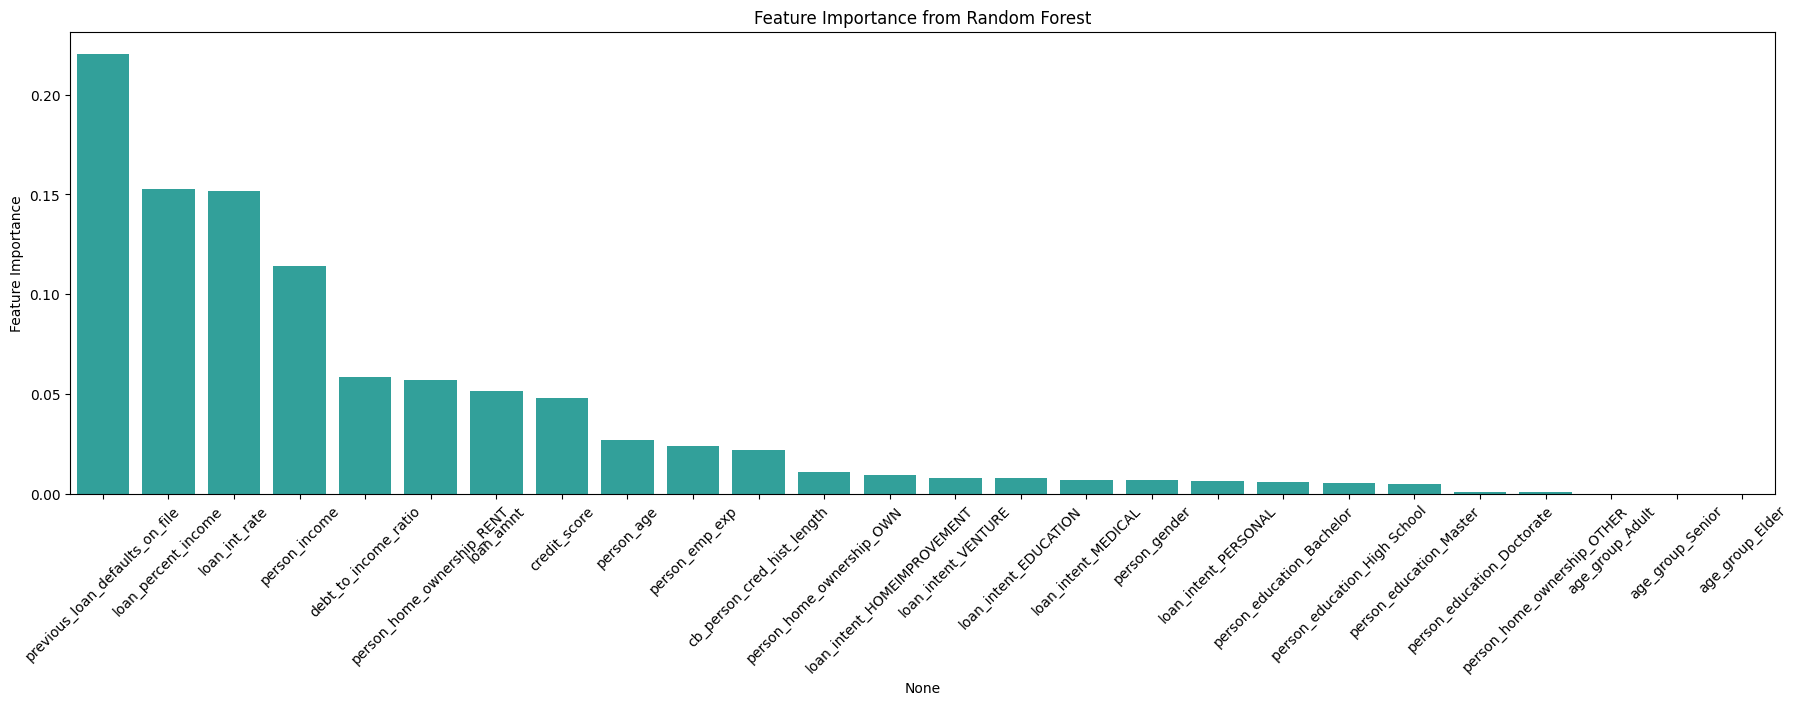

In [ ]:
# Model-Based Feature Selection with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(22,6))
sns.barplot(x=importances.index, y=importances.values, color="lightseagreen")
plt.xticks(rotation=45)
plt.ylabel("Feature Importance")
plt.title("Feature Importance from Random Forest")
plt.show()

* we picked Variance threshold and random forest as
our methods for feature selection



**Select methos 1: Variance threshold **

In [ ]:
# Drop low varaince features with varince threshold
from sklearn.feature_selection import VarianceThreshold

# Apply Variance Threshold
var_thresh = VarianceThreshold(threshold=0.01)  # threshold=0 means drop only constant cols
X_var = var_thresh.fit_transform(X)
kept_after_var = X.columns[var_thresh.get_support()]

print("Features kept after Variance Threshold:", kept_after_var.tolist())

# Identify dropped ones
dropped_by_var = [col for col in X.columns if col not in kept_after_var]
print("Features dropped by Variance Threshold:", dropped_by_var)

Features kept after Variance Threshold: ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio']
Features dropped by Variance Threshold: ['person_home_ownership_OTHER', 'age_group_Adult', 'age_group_Senior', 'age_group_Elder']


In [ ]:
print("Original shape:", df_final.shape)
print(df_final.head())

Original shape: (42782, 27)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301              0       0.033638       -0.893596   4.257362   
1   -1.124179              0      -1.805044       -0.893596  -1.369744   
2   -0.444668              0      -1.800237       -0.385040  -0.624980   
3   -0.784423              0       0.274159       -0.893596   4.257362   
4   -0.614545              1      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                               0  ...   


In [ ]:
# After dropping low variance features
X_var_df = pd.DataFrame(X_var, columns=kept_after_var)
print("Shape after VarianceThreshold:", X_var_df.shape)
print(X_var_df.head())

Shape after VarianceThreshold: (42782, 22)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301            0.0       0.033638       -0.893596   4.257362   
1   -1.124179            0.0      -1.805044       -0.893596  -1.369744   
2   -0.444668            0.0      -1.800237       -0.385040  -0.624980   
3   -0.784423            0.0       0.274159       -0.893596   4.257362   
4   -0.614545            1.0      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                          

In [ ]:
df = X_var_df.copy()

In [ ]:
print("New shape:", df.shape)
print(df.head())

New shape: (42782, 22)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301            0.0       0.033638       -0.893596   4.257362   
1   -1.124179            0.0      -1.805044       -0.893596  -1.369744   
2   -0.444668            0.0      -1.800237       -0.385040  -0.624980   
3   -0.784423            0.0       0.274159       -0.893596   4.257362   
4   -0.614545            1.0      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                             0.0  ...   
1    

In [ ]:
print(df.dtypes)

person_age                        float64
person_gender                     float64
person_income                     float64
person_emp_exp                    float64
loan_amnt                         float64
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                      float64
previous_loan_defaults_on_file    float64
person_education_Bachelor         float64
person_education_Doctorate        float64
person_education_High School      float64
person_education_Master           float64
person_home_ownership_OWN         float64
person_home_ownership_RENT        float64
loan_intent_EDUCATION             float64
loan_intent_HOMEIMPROVEMENT       float64
loan_intent_MEDICAL               float64
loan_intent_PERSONAL              float64
loan_intent_VENTURE               float64
debt_to_income_ratio              float64
dtype: object


**Select method 2: Random Forest**

In [ ]:
# Train Random Forest on variance-thresholded features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(df, y)

# Select features above median importance
model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = df.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


In [ ]:
# Create dataset with only selected features
X_final = df[selected_features]

**Final output after feature selection**

In [ ]:
print("New shape:", X_final.shape)
print(X_final.head())

New shape: (42782, 11)
   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0   -0.954301       0.033638       -0.893596   4.257362       1.689572   
1   -1.124179      -1.805044       -0.893596  -1.369744       0.049385   
2   -0.444668      -1.800237       -0.385040  -0.624980       0.630845   
3   -0.784423       0.274159       -0.893596   4.257362       1.424050   
4   -0.614545      -0.145496       -0.724077   4.257362       1.101390   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0             3.964332                   -0.726387     -1.414790   
1            -0.724671                   -0.987541     -2.545274   
2             3.392503                   -0.726387      0.052856   
3             3.392503                   -0.987541      0.846178   
4             4.421796                   -0.465233     -0.918964   

   previous_loan_defaults_on_file  person_home_ownership_RENT  \
0                             0.0                         